In [1]:
# Veri analizi
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Doğal Dil İşleme (NLP)
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

# Metin benzerliği ve özellik çıkarımı
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Word2Vec
from gensim.models import Word2Vec

# Gerekli NLTK kaynakları
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ERCAN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ERCAN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ERCAN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ERCAN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\ERCAN\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [3]:
# PriceRunner veri setini yükle
df = pd.read_csv("pricerunner_aggregate.csv")

# Veri setinin boyutunu incele
print("Veri setinin satır ve sütun sayısı:", df.shape)

# İlk 5 kaydı görüntüle
print("\nİlk 5 kayıt:")
print(df.head())

# Sütun bilgilerini incele
print("\nSütun bilgileri:")
print(df.info())

Veri setinin satır ve sütun sayısı: (35311, 7)

İlk 5 kayıt:
   Product ID                                      Product Title  Vendor ID  \
0           1                    apple iphone 8 plus 64gb silver          1   
1           2                apple iphone 8 plus 64 gb spacegrau          2   
2           3  apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...          3   
3           4                apple iphone 8 plus 64gb space grey          4   
4           5  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...          5   

   Cluster ID             Cluster Label  Category ID Category Label  
0           1  Apple iPhone 8 Plus 64GB         2612  Mobile Phones  
1           1  Apple iPhone 8 Plus 64GB         2612  Mobile Phones  
2           1  Apple iPhone 8 Plus 64GB         2612  Mobile Phones  
3           1  Apple iPhone 8 Plus 64GB         2612  Mobile Phones  
4           1  Apple iPhone 8 Plus 64GB         2612  Mobile Phones  

Sütun bilgileri:
<class 'pandas.core.frame.

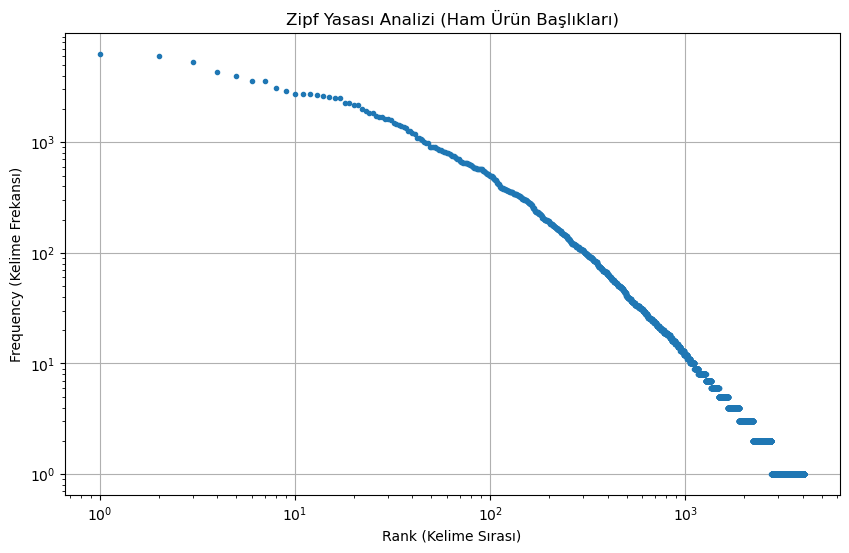

In [5]:
# Gerekli kütüphaneler
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Ürün başlıklarını tek bir metin haline getir
all_text = ' '.join(df['Product Title'].astype(str))

# Kelimelere ayır ve küçük harfe çevir
tokens = [
    word.lower()
    for word in word_tokenize(all_text)
    if word.isalpha()
]

# Kelime frekanslarını hesapla
word_counts = Counter(tokens)

# Kelimeleri frekanslarına göre sırala
sorted_word_counts = word_counts.most_common()

# Rank ve frekans değerlerini oluştur
ranks = np.arange(1, len(sorted_word_counts) + 1)
frequencies = [count for word, count in sorted_word_counts]

# Zipf Yasası grafiği
plt.figure(figsize=(10, 6))
plt.loglog(ranks, frequencies, marker='.', linestyle='None')

plt.title("Zipf Yasası Analizi (Ham Ürün Başlıkları)")
plt.xlabel("Rank (Kelime Sırası)")
plt.ylabel("Frequency (Kelime Frekansı)")
plt.grid(True)
plt.show()

In [13]:
import re

def clean_text(text):
    if pd.isna(text):
        return ""

    # Küçük harfe dönüştür
    text = text.lower()

    # HTML etiketlerini temizle
    text = re.sub(r'<[^>]+>', ' ', text)

    # Para birimi ifadelerini temizle
    text = re.sub(r'[$£€]', ' ', text)
    text = re.sub(r'\b(usd|gbp|eur)\b', ' ', text)

    # Sayı ile birim arasındaki boşluğu kaldır
    text = re.sub(r'(\d+)\s+(gb|tb|mb|kg|mg|ml|cm|mm)', r'\1\2', text)

    # Noktalama işaretlerini temizle
    # Harf, rakam ve boşlukları koru
    text = re.sub(r'[^\w\s.]', ' ', text) 

    # Sayıların arasındaki ondalık noktaları koru
    text = re.sub(r'(?<=\d)\.(?=\d)', 'DECIMALPOINT', text)
    text = re.sub(r'\.', ' ', text)
    text = text.replace('DECIMALPOINT', '.')

    # Fazla boşlukları temizle
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Temizlenmiş ürün başlıklarını yeni sütuna kaydet
df['Cleaned Title'] = df['Product Title'].apply(clean_text)

# Örnek sonuçları incele
print(df[['Product Title', 'Cleaned Title']].head(10))

                                       Product Title  \
0                    apple iphone 8 plus 64gb silver   
1                apple iphone 8 plus 64 gb spacegrau   
2  apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...   
3                apple iphone 8 plus 64gb space grey   
4  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...   
5  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...   
6               apple iphone 8 plus 64 gb space grey   
7                apple iphone 8 plus 64gb space grey   
8                apple iphone 8 plus 64gb space grey   
9                apple iphone 8 plus 64gb space grey   

                                       Cleaned Title  
0                    apple iphone 8 plus 64gb silver  
1                 apple iphone 8 plus 64gb spacegrau  
2  apple mq8n2b a iphone 8 plus 64gb 5.5 12mp sim...  
3                apple iphone 8 plus 64gb space grey  
4  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...  
5  apple iphone 8 plus gold 5.5 64gb 4g unlocked ... 

In [15]:
# Gerekli NLTK bileşenleri
from nltk.corpus import wordnet
from nltk import pos_tag

# Lemmatizer başlat
lemmatizer = WordNetLemmatizer()

# POS etiketlerini WordNet formatına dönüştür
def get_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Lemmatization fonksiyonu
def lemmatize_text(text):
    tokens = word_tokenize(text)
    tags = pos_tag(tokens)

    lemmatized_words = [
        lemmatizer.lemmatize(word, get_pos(tag))
        for word, tag in tags
    ]

    return " ".join(lemmatized_words)

# Temizlenmiş başlıklara Lemmatization uygula
df['Lemmatized Title'] = df['Cleaned Title'].apply(lemmatize_text)

# Sonuçları karşılaştır
print(df[['Product Title', 'Cleaned Title', 'Lemmatized Title']].head(10))

                                       Product Title  \
0                    apple iphone 8 plus 64gb silver   
1                apple iphone 8 plus 64 gb spacegrau   
2  apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...   
3                apple iphone 8 plus 64gb space grey   
4  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...   
5  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...   
6               apple iphone 8 plus 64 gb space grey   
7                apple iphone 8 plus 64gb space grey   
8                apple iphone 8 plus 64gb space grey   
9                apple iphone 8 plus 64gb space grey   

                                       Cleaned Title  \
0                    apple iphone 8 plus 64gb silver   
1                 apple iphone 8 plus 64gb spacegrau   
2  apple mq8n2b a iphone 8 plus 64gb 5.5 12mp sim...   
3                apple iphone 8 plus 64gb space grey   
4  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...   
5  apple iphone 8 plus gold 5.5 64gb 4g unlocke

In [17]:
# Gerekli araçları başlat
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

# İngilizce stopword listesi
stop_words = set(stopwords.words('english'))

# Ürün eşleştirmede anlamlı olabilecek kelimeleri koru
stop_words -= {'no', 'not', 'nor', 'without'}

# Metin ön işleme fonksiyonu
def preprocess_sentence(sentence):

    # Tokenization
    tokens = word_tokenize(sentence)

    # Stopword temizleme
    filtered_tokens = [
        token.lower()
        for token in tokens
        if token.isalnum() and token.lower() not in stop_words
    ]

    # POS etiketleme
    alphabetic_tokens = [
        token for token in filtered_tokens if token.isalpha()
    ]

    pos_tags = pos_tag(alphabetic_tokens)
    pos_dict = {
        word: tag for word, tag in pos_tags
    }

    # Lemmatization
    lemmatized_tokens = [
        lemmatizer.lemmatize(
            token,
            get_pos(pos_dict[token])
        ) if token.isalpha() else token
        for token in filtered_tokens
    ]

    # Stemming
    stemmed_tokens = [
        stemmer.stem(token) if token.isalpha() else token
        for token in filtered_tokens
    ]

    return filtered_tokens, lemmatized_tokens, stemmed_tokens


# PriceRunner verisine uygula
tokenized_corpus = []
tokenized_corpus_lemmatized = []
tokenized_corpus_stemmed = []

for sentence in df['Cleaned Title'].fillna(''):

    tokens, lemmatized_tokens, stemmed_tokens = preprocess_sentence(sentence)

    tokenized_corpus.append(tokens)
    tokenized_corpus_lemmatized.append(lemmatized_tokens)
    tokenized_corpus_stemmed.append(stemmed_tokens)


# İlk 3 sonucu karşılaştır
for i in range(3):

    print(f"\nÜrün {i+1}")
    print("Orijinal:", df['Product Title'].iloc[i])
    print("Tokenized:", tokenized_corpus[i])
    print("Lemmatized:", tokenized_corpus_lemmatized[i])
    print("Stemmed:", tokenized_corpus_stemmed[i])


Ürün 1
Orijinal: apple iphone 8 plus 64gb silver
Tokenized: ['apple', 'iphone', '8', 'plus', '64gb', 'silver']
Lemmatized: ['apple', 'iphone', '8', 'plus', '64gb', 'silver']
Stemmed: ['appl', 'iphon', '8', 'plu', '64gb', 'silver']

Ürün 2
Orijinal: apple iphone 8 plus 64 gb spacegrau
Tokenized: ['apple', 'iphone', '8', 'plus', '64gb', 'spacegrau']
Lemmatized: ['apple', 'iphone', '8', 'plus', '64gb', 'spacegrau']
Stemmed: ['appl', 'iphon', '8', 'plu', '64gb', 'spacegrau']

Ürün 3
Orijinal: apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphone in gold
Tokenized: ['apple', 'mq8n2b', 'iphone', '8', 'plus', '64gb', '12mp', 'sim', 'free', 'smartphone', 'gold']
Lemmatized: ['apple', 'mq8n2b', 'iphone', '8', 'plus', '64gb', '12mp', 'sim', 'free', 'smartphone', 'gold']
Stemmed: ['appl', 'mq8n2b', 'iphon', '8', 'plu', '64gb', '12mp', 'sim', 'free', 'smartphon', 'gold']


In [19]:
# Lemmatization sonuçlarını DataFrame'e ekle
df['Tokens Lemmatized'] = tokenized_corpus_lemmatized

# Lemmatization sonuçlarını CSV dosyasına kaydet
df['Tokens Lemmatized'].apply(
    lambda tokens: ' '.join(tokens)
).to_csv(
    'lemmatized_sentences.csv',
    index=False,
    header=['lemmatized_text']
)


# Stemming sonuçlarını DataFrame'e ekle
df['Tokens Stemmed'] = tokenized_corpus_stemmed

# Stemming sonuçlarını CSV dosyasına kaydet
df['Tokens Stemmed'].apply(
    lambda tokens: ' '.join(tokens)
).to_csv(
    'stemmed_sentences.csv',
    index=False,
    header=['stemmed_text']
)


# Sonuçları kontrol et
print("Temizlenmiş ve işlenmiş verinin ilk 5 satırı:")

print(df[[
    'Product Title',
    'Tokens Lemmatized',
    'Tokens Stemmed'
]].head(5))

Temizlenmiş ve işlenmiş verinin ilk 5 satırı:
                                       Product Title  \
0                    apple iphone 8 plus 64gb silver   
1                apple iphone 8 plus 64 gb spacegrau   
2  apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...   
3                apple iphone 8 plus 64gb space grey   
4  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...   

                                   Tokens Lemmatized  \
0             [apple, iphone, 8, plus, 64gb, silver]   
1          [apple, iphone, 8, plus, 64gb, spacegrau]   
2  [apple, mq8n2b, iphone, 8, plus, 64gb, 12mp, s...   
3        [apple, iphone, 8, plus, 64gb, space, grey]   
4  [apple, iphone, 8, plus, gold, 64gb, 4g, unloc...   

                                      Tokens Stemmed  
0                [appl, iphon, 8, plu, 64gb, silver]  
1             [appl, iphon, 8, plu, 64gb, spacegrau]  
2  [appl, mq8n2b, iphon, 8, plu, 64gb, 12mp, sim,...  
3           [appl, iphon, 8, plu, 64gb, space, grey]  
4  [a

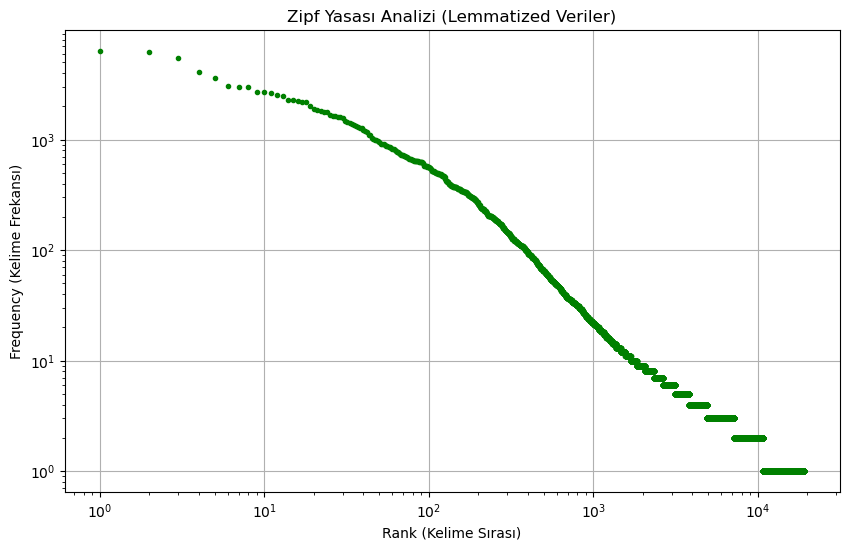

In [21]:
# Lemmatize edilmiş kelimeleri birleştir
lemmatized_tokens = [
    token
    for sublist in tokenized_corpus_lemmatized
    for token in sublist
]

# Kelime frekanslarını hesapla
lemmatized_counts = Counter(lemmatized_tokens)

# Frekanslara göre sırala
sorted_lemmatized = lemmatized_counts.most_common()

# Rank ve frekans değerlerini oluştur
ranks_lem = np.arange(1, len(sorted_lemmatized) + 1)
frequencies_lem = [
    count for word, count in sorted_lemmatized
]

# Zipf grafiği
plt.figure(figsize=(10, 6))
plt.loglog(
    ranks_lem,
    frequencies_lem,
    marker='.',
    linestyle='None',
    color='green'
)

plt.title("Zipf Yasası Analizi (Lemmatized Veriler)")
plt.xlabel("Rank (Kelime Sırası)")
plt.ylabel("Frequency (Kelime Frekansı)")
plt.grid(True)
plt.show()

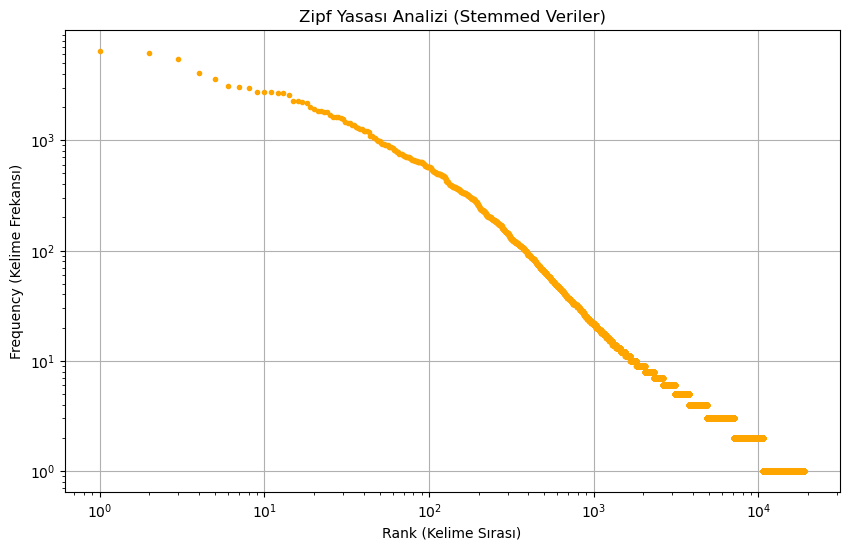

In [23]:
# Stemlenmiş kelimeleri birleştir
stemmed_tokens = [
    token
    for sublist in tokenized_corpus_stemmed
    for token in sublist
]

# Kelime frekanslarını hesapla
stemmed_counts = Counter(stemmed_tokens)

# Frekanslara göre sırala
sorted_stemmed = stemmed_counts.most_common()

# Rank ve frekans değerlerini oluştur
ranks_stem = np.arange(1, len(sorted_stemmed) + 1)
frequencies_stem = [
    count for word, count in sorted_stemmed
]

# Zipf grafiği
plt.figure(figsize=(10, 6))
plt.loglog(
    ranks_stem,
    frequencies_stem,
    marker='.',
    linestyle='None',
    color='orange'
)

plt.title("Zipf Yasası Analizi (Stemmed Veriler)")
plt.xlabel("Rank (Kelime Sırası)")
plt.ylabel("Frequency (Kelime Frekansı)")
plt.grid(True)
plt.show()

In [25]:
# Lemmatize edilmiş token listelerini metne dönüştür
lemmatized_texts = [
    ' '.join(tokens)
    for tokens in tokenized_corpus_lemmatized
]

# İlk 3 metni görüntüle
print("İlk 3 Lemmatized Metin:\n")

for text in lemmatized_texts[:3]:
    print(text)
    print("-" * 50)

İlk 3 Lemmatized Metin:

apple iphone 8 plus 64gb silver
--------------------------------------------------
apple iphone 8 plus 64gb spacegrau
--------------------------------------------------
apple mq8n2b iphone 8 plus 64gb 12mp sim free smartphone gold
--------------------------------------------------


In [30]:
# TF-IDF vektörizerını başlat
vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

# Lemmatized metinlerden TF-IDF matrisi oluştur
tfidf_matrix = vectorizer.fit_transform(lemmatized_texts)

# Kelimeleri al
feature_names = vectorizer.get_feature_names_out()

# Matris boyutunu kontrol et
print("TF-IDF matris boyutu:", tfidf_matrix.shape)
print("Toplam kelime sayısı:", len(feature_names))

# İlk 5 satırı görüntüle
tfidf_preview = pd.DataFrame(
    tfidf_matrix[:5].toarray(),
    columns=feature_names
)

print("\nİlk 5 ürünün TF-IDF değerleri:")
print(tfidf_preview)

# Seyrek matrisi uzun formatlı CSV olarak kaydet
coo_matrix = tfidf_matrix.tocoo()

tfidf_lemmatized_sparse = pd.DataFrame({
    'Product ID': df['Product ID'].to_numpy()[coo_matrix.row],
    'Word': feature_names[coo_matrix.col],
    'TF-IDF Score': coo_matrix.data
})

tfidf_lemmatized_sparse.to_csv(
    "tfidf_lemmatized.csv",
    index=False
)

print("\ntfidf_lemmatized.csv dosyası kaydedildi.")

TF-IDF matris boyutu: (35311, 19157)
Toplam kelime sayısı: 19157

İlk 5 ürünün TF-IDF değerleri:
     0   00  000  0000  001  002b269  0030  004  005  008  ...  zwi71201wa  \
0  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
1  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
2  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
3  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
4  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   

   zwi71401wa  zwm496w  zwm696w  zwt71201wa  zwt7142wa  zwy61223ki  \
0         0.0      0.0      0.0         0.0        0.0         0.0   
1         0.0      0.0      0.0         0.0        0.0         0.0   
2         0.0      0.0      0.0         0.0        0.0         0.0   
3         0.0      0.0      0.0         0.0        0.0         0.0   
4         0.0      0.0      0.0         0.0        0.0         0.0   

   zwy61225wi

In [32]:
# Stemmed token listelerini metne dönüştür
stemmed_texts = [
    ' '.join(tokens)
    for tokens in tokenized_corpus_stemmed
]

# TF-IDF vektörizerını başlat
vectorizer_stem = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

# Stemmed metinlerden TF-IDF matrisi oluştur
tfidf_matrix_stem = vectorizer_stem.fit_transform(stemmed_texts)

# Kelimeleri al
feature_names_stem = vectorizer_stem.get_feature_names_out()

# Matris boyutunu kontrol et
print("Stemmed TF-IDF matris boyutu:", tfidf_matrix_stem.shape)
print("Toplam kelime sayısı:", len(feature_names_stem))

# İlk 5 ürünün TF-IDF değerlerini görüntüle
tfidf_preview_stem = pd.DataFrame(
    tfidf_matrix_stem[:5].toarray(),
    columns=feature_names_stem
)

print("\nİlk 5 ürünün Stemmed TF-IDF değerleri:")
print(tfidf_preview_stem)

# Seyrek matrisi uzun formatlı CSV olarak kaydet
coo_matrix = tfidf_matrix_stem.tocoo()

tfidf_stemmed_sparse = pd.DataFrame({
    'Product ID': df['Product ID'].to_numpy()[coo_matrix.row],
    'Word': feature_names_stem[coo_matrix.col],
    'TF-IDF Score': coo_matrix.data
})

tfidf_stemmed_sparse.to_csv(
    "tfidf_stemmed.csv",
    index=False
)

print("\ntfidf_stemmed.csv dosyası kaydedildi.")

Stemmed TF-IDF matris boyutu: (35311, 18990)
Toplam kelime sayısı: 18990

İlk 5 ürünün Stemmed TF-IDF değerleri:
     0   00  000  0000  001  002b269  0030  004  005  008  ...  zwi71201wa  \
0  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
1  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
2  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
3  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   
4  0.0  0.0  0.0   0.0  0.0      0.0   0.0  0.0  0.0  0.0  ...         0.0   

   zwi71401wa  zwm496w  zwm696w  zwt71201wa  zwt7142wa  zwy61223ki  \
0         0.0      0.0      0.0         0.0        0.0         0.0   
1         0.0      0.0      0.0         0.0        0.0         0.0   
2         0.0      0.0      0.0         0.0        0.0         0.0   
3         0.0      0.0      0.0         0.0        0.0         0.0   
4         0.0      0.0      0.0         0.0        0.0         0.0  

In [34]:
# Lemmatize edilmiş ürün başlıkları üzerinden TF-IDF hesaplama
tfidf = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")

tfidf_matrix = tfidf.fit_transform(
    df['Lemmatized Title'].fillna('')
)

feature_names = tfidf.get_feature_names_out()

print("İlk ürün başlığında en yüksek TF-IDF skoruna sahip 5 kelime:")

first_row = tfidf_matrix[0].toarray().flatten()
top_indices = first_row.argsort()[-5:][::-1]

for index in top_indices:
    print(f"{feature_names[index]}: {first_row[index]:.4f}")

İlk ürün başlığında en yüksek TF-IDF skoruna sahip 5 kelime:
apple: 0.4455
plus: 0.4433
iphone: 0.4260
64gb: 0.4255
8: 0.3652


In [36]:
# Stemmed token listelerini metne dönüştür
stemmed_texts = [
    ' '.join(tokens)
    for tokens in tokenized_corpus_stemmed
]

# TF-IDF vektörizerını başlat
tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

# Stemmed metinlerden TF-IDF matrisi oluştur
tfidf_matrix_stem = tfidf.fit_transform(stemmed_texts)

# Kelimeleri al
feature_names_stem = tfidf.get_feature_names_out()

print("Stemmed TF-IDF matris boyutu:", tfidf_matrix_stem.shape)

# İlk ürünün en yüksek TF-IDF skoruna sahip 5 kelimesini bul
first_row = tfidf_matrix_stem.getrow(0)

top_indices = first_row.data.argsort()[-5:][::-1]

print("\nİlk ürün başlığında en yüksek TF-IDF skoruna sahip 5 kelime:")

for index in top_indices:
    word_index = first_row.indices[index]
    print(
        f"{feature_names_stem[word_index]}: "
        f"{first_row.data[index]:.4f}"
    )

Stemmed TF-IDF matris boyutu: (35311, 18990)

İlk ürün başlığında en yüksek TF-IDF skoruna sahip 5 kelime:
appl: 0.4402
plu: 0.4380
iphon: 0.4209
64gb: 0.4204
8: 0.3924


In [38]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# 1. TF-IDF matrisini oluştur
vectorizer_stem = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

tfidf_matrix_stem = vectorizer_stem.fit_transform(stemmed_texts)

# 2. Gruplama için değişkenleri hazırla
groups = []
visited = set()
threshold = 0.85

# 3. Benzerlikleri parça parça hesapla
batch_size = 100

for start in range(0, len(stemmed_texts), batch_size):

    end = min(start + batch_size, len(stemmed_texts))

    # Sadece mevcut parçanın benzerliklerini hesapla
    cosine_sim_batch = cosine_similarity(
        tfidf_matrix_stem[start:end],
        tfidf_matrix_stem
    )

    for local_idx in range(end - start):

        i = start + local_idx

        if i in visited:
            continue

        group = [i]
        visited.add(i)

        similar_indices = np.where(
            cosine_sim_batch[local_idx] > threshold
        )[0]

        for j in similar_indices:

            if j > i and j not in visited:
                group.append(j)
                visited.add(j)

        groups.append(group)

    del cosine_sim_batch

# 4. group_id değerlerini oluştur
group_ids = [None] * len(stemmed_texts)

for group_id, group in enumerate(groups):
    for idx in group:
        group_ids[idx] = group_id

# 5. Grup bilgilerini ana veri setine ekle
df['group_id_stemmed'] = group_ids

# 6. Sonuçları kontrol et
print("Toplam grup sayısı:", len(groups))
print("\nİlk 20 ürünün grupları:")

print(
    df[['Product Title', 'group_id_stemmed']].head(20)
)

Toplam grup sayısı: 27332

İlk 20 ürünün grupları:
                                        Product Title  group_id_stemmed
0                     apple iphone 8 plus 64gb silver                 0
1                 apple iphone 8 plus 64 gb spacegrau                 1
2   apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...                 2
3                 apple iphone 8 plus 64gb space grey                 3
4   apple iphone 8 plus gold 5.5 64gb 4g unlocked ...                 4
5   apple iphone 8 plus gold 5.5 64gb 4g unlocked ...                 4
6                apple iphone 8 plus 64 gb space grey                 3
7                 apple iphone 8 plus 64gb space grey                 3
8                 apple iphone 8 plus 64gb space grey                 3
9                 apple iphone 8 plus 64gb space grey                 3
10  apple iphone 8 plus 5.5 single sim 4g 64gb silver                 5
11    sim free iphone 8 plus 64gb by apple space grey                 3
12           

In [46]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# 1. PriceRunner veri setinden bir kelime seç
word = "iphone"

# 2. Kelimenin indeksini bul
feature_names = vectorizer.get_feature_names_out()

if word not in feature_names:
    print(f"'{word}' kelimesi TF-IDF sözlüğünde bulunamadı.")

else:
    word_index = np.where(feature_names == word)[0][0]

    # 3. Seçilen kelimenin TF-IDF vektörünü al
    word_vector = tfidf_matrix.T[word_index]

    print(f"'{word}' kelimesinin TF-IDF vektörü:")
    print(word_vector)

    # 4. Diğer kelimelerle kosinüs benzerliğini hesapla
    similarities = cosine_similarity(
        word_vector,
        tfidf_matrix.T
    ).flatten()

    # 5. En benzer 5 kelimeyi bul
    top_indices = similarities.argsort()[::-1]

    top_indices = [
        idx for idx in top_indices
        if idx != word_index
    ][:5]

    # 6. Sonuçları göster
    print(f"\n'{word}' kelimesine en çok benzeyen 5 kelime:")

    for idx in top_indices:
        print(f"{feature_names[idx]}: {similarities[idx]:.4f}")

'iphone' kelimesinin TF-IDF vektörü:
  (0, 0)	0.42089561122859187
  (0, 1)	0.35598725175193924
  (0, 2)	0.26334265035125715
  (0, 3)	0.3579963924824
  (0, 4)	0.32756723041760133
  (0, 5)	0.32756723041760133
  (0, 6)	0.3579963924824
  (0, 7)	0.3579963924824
  (0, 8)	0.3579963924824
  (0, 9)	0.3579963924824
  (0, 10)	0.34592364584299723
  (0, 11)	0.33686263463670507
  (0, 12)	0.38036001389292745
  (0, 13)	0.33610636627496254
  (0, 14)	0.33608262481297274
  (0, 15)	0.42089561122859187
  (0, 16)	0.3791211263826967
  (0, 17)	0.2532653117416284
  (0, 18)	0.26212194908677
  (0, 19)	0.38607309005139184
  (0, 20)	0.49716766502366827
  (0, 21)	0.3280522297626249
  (0, 22)	0.22292903774750586
  (0, 23)	0.24638766656829508
  (0, 24)	0.3436779713948136
  :	:
  (0, 2748)	0.38757547042454066
  (0, 2749)	0.31824773219496866
  (0, 2750)	0.3753232571773627
  (0, 2751)	0.45003794972859223
  (0, 2784)	0.4215343964847662
  (0, 2809)	0.2138629821697295
  (0, 2810)	0.3530414575998706
  (0, 2811)	0.2761822487

In [48]:
# PriceRunner veri setindeki ürün başlıklarını al
texts = df['Product Title'].dropna().astype(str).tolist()

# Ürün başlıklarını tokenize et
tokenized_texts = [
    word_tokenize(text.lower())
    for text in texts
]

# Kontrol
print("Toplam ürün başlığı:", len(texts))

print("\nİlk 5 tokenize edilmiş ürün başlığı:")
for tokens in tokenized_texts[:5]:
    print(tokens)

Toplam ürün başlığı: 35311

İlk 5 tokenize edilmiş ürün başlığı:
['apple', 'iphone', '8', 'plus', '64gb', 'silver']
['apple', 'iphone', '8', 'plus', '64', 'gb', 'spacegrau']
['apple', 'mq8n2b/a', 'iphone', '8', 'plus', '64gb', '5.5', '12mp', 'sim', 'free', 'smartphone', 'in', 'gold']
['apple', 'iphone', '8', 'plus', '64gb', 'space', 'grey']
['apple', 'iphone', '8', 'plus', 'gold', '5.5', '64gb', '4g', 'unlocked', 'sim', 'free']


In [50]:
# 1. Tokenized corpus'ları oluştur
tokenized_corpus_lemmatized = tokenized_corpus_lemmatized
tokenized_corpus_stemmed = tokenized_corpus_stemmed

# Boş listeleri çıkar
tokenized_corpus_lemmatized = [
    tokens for tokens in tokenized_corpus_lemmatized if tokens
]

tokenized_corpus_stemmed = [
    tokens for tokens in tokenized_corpus_stemmed if tokens
]

# 2. Parametre setleri
parameters = [
    {'model_type': 'cbow',     'window': 2, 'vector_size': 100},
    {'model_type': 'skipgram', 'window': 2, 'vector_size': 100},
    {'model_type': 'cbow',     'window': 4, 'vector_size': 100},
    {'model_type': 'skipgram', 'window': 4, 'vector_size': 100},
    {'model_type': 'cbow',     'window': 2, 'vector_size': 300},
    {'model_type': 'skipgram', 'window': 2, 'vector_size': 300},
    {'model_type': 'cbow',     'window': 4, 'vector_size': 300},
    {'model_type': 'skipgram', 'window': 4, 'vector_size': 300}
]

# 3. Model eğitme ve kaydetme fonksiyonu
def train_and_save_model(corpus, params, prefix):

    sg_flag = 1 if params['model_type'] == 'skipgram' else 0

    model = Word2Vec(
        sentences=corpus,
        vector_size=params['vector_size'],
        window=params['window'],
        min_count=1,
        sg=sg_flag,
        workers=2,
        epochs=10,
        seed=42
    )

    fname = (
        f"{prefix}_{params['model_type']}"
        f"_w{params['window']}_d{params['vector_size']}.model"
    )

    model.save(fname)

    print(f"Model kaydedildi: {fname}")

    # Model belleğini serbest bırak
    del model


# 4. Lemmatized modelleri eğit ve kaydet
for p in parameters:
    train_and_save_model(
        tokenized_corpus_lemmatized,
        p,
        "lemmatized_model"
    )

# 5. Stemmed modelleri eğit ve kaydet
for p in parameters:
    train_and_save_model(
        tokenized_corpus_stemmed,
        p,
        "stemmed_model"
    )

Model kaydedildi: lemmatized_model_cbow_w2_d100.model
Model kaydedildi: lemmatized_model_skipgram_w2_d100.model
Model kaydedildi: lemmatized_model_cbow_w4_d100.model
Model kaydedildi: lemmatized_model_skipgram_w4_d100.model
Model kaydedildi: lemmatized_model_cbow_w2_d300.model
Model kaydedildi: lemmatized_model_skipgram_w2_d300.model
Model kaydedildi: lemmatized_model_cbow_w4_d300.model
Model kaydedildi: lemmatized_model_skipgram_w4_d300.model
Model kaydedildi: stemmed_model_cbow_w2_d100.model
Model kaydedildi: stemmed_model_skipgram_w2_d100.model
Model kaydedildi: stemmed_model_cbow_w4_d100.model
Model kaydedildi: stemmed_model_skipgram_w4_d100.model
Model kaydedildi: stemmed_model_cbow_w2_d300.model
Model kaydedildi: stemmed_model_skipgram_w2_d300.model
Model kaydedildi: stemmed_model_cbow_w4_d300.model
Model kaydedildi: stemmed_model_skipgram_w4_d300.model


In [52]:
# 1. Eğitilmiş modelleri yükle
model_1 = Word2Vec.load("lemmatized_model_cbow_w2_d100.model")
model_2 = Word2Vec.load("stemmed_model_skipgram_w4_d100.model")
model_3 = Word2Vec.load("lemmatized_model_skipgram_w4_d300.model")


# 2. Benzer kelimeleri yazdıran fonksiyon
def print_similar_words(model, model_name, keyword="iphone"):

    try:
        similarity = model.wv.most_similar(keyword, topn=3)

        print(f"\n{model_name} Modeli")
        print(f"'{keyword}' kelimesine en benzer 3 kelime:")

        for word, score in similarity:
            print(f"Kelime: {word}, Benzerlik Skoru: {score:.4f}")

    except KeyError:
        print(
            f"\n{model_name} Modeli: "
            f"'{keyword}' kelimesi modelin sözlüğünde bulunamadı."
        )


# 3. Her model için benzer kelimeleri bul
print_similar_words(
    model_1, "Lemmatized CBOW Window 2 Dim 100"
)

print_similar_words(
    model_2, "Stemmed Skip-gram Window 4 Dim 100"
)

print_similar_words(
    model_3, "Lemmatized Skip-gram Window 4 Dim 300",
    keyword="iphon"
)


Lemmatized CBOW Window 2 Dim 100 Modeli
'iphone' kelimesine en benzer 3 kelime:
Kelime: 1700x, Benzerlik Skoru: 0.8944
Kelime: 640, Benzerlik Skoru: 0.8640
Kelime: operat, Benzerlik Skoru: 0.8633

Stemmed Skip-gram Window 4 Dim 100 Modeli: 'iphone' kelimesi modelin sözlüğünde bulunamadı.

Lemmatized Skip-gram Window 4 Dim 300 Modeli: 'iphon' kelimesi modelin sözlüğünde bulunamadı.


In [56]:
# Her model için doğru kelime biçimini kullan
print_similar_words(
    model_1,
    "Lemmatized CBOW Window 2 Dim 100",
    keyword="iphone"
)

print_similar_words(
    model_2,
    "Stemmed Skipgram Window 4 Dim 100",
    keyword="iphon"
)

print_similar_words(
    model_3,
    "Lemmatized Skipgram Window 4 Dim 300",
    keyword="iphone"
)
    


Lemmatized CBOW Window 2 Dim 100 Modeli
'iphone' kelimesine en benzer 3 kelime:
Kelime: 1700x, Benzerlik Skoru: 0.8944
Kelime: 640, Benzerlik Skoru: 0.8640
Kelime: operat, Benzerlik Skoru: 0.8633

Stemmed Skipgram Window 4 Dim 100 Modeli
'iphon' kelimesine en benzer 3 kelime:
Kelime: appl, Benzerlik Skoru: 0.9086
Kelime: mnqq2b, Benzerlik Skoru: 0.8605
Kelime: xs, Benzerlik Skoru: 0.8546

Lemmatized Skipgram Window 4 Dim 300 Modeli
'iphone' kelimesine en benzer 3 kelime:
Kelime: apple, Benzerlik Skoru: 0.9346
Kelime: 6s, Benzerlik Skoru: 0.8856
Kelime: mnqq2b, Benzerlik Skoru: 0.8802


In [60]:
import pandas as pd

# Lemmatized metinleri CSV dosyasından yükle
lemmatized_df = pd.read_csv("lemmatized_sentences.csv")

# İlk 5 satırı göster
print("Lemmatized metinlerin ilk 5 satırı:")
print(lemmatized_df.head())

Lemmatized metinlerin ilk 5 satırı:
                                     lemmatized_text
0                    apple iphone 8 plus 64gb silver
1                 apple iphone 8 plus 64gb spacegrau
2  apple mq8n2b iphone 8 plus 64gb 12mp sim free ...
3                apple iphone 8 plus 64gb space grey
4  apple iphone 8 plus gold 64gb 4g unlocked sim ...


In [64]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# 1. İlk ürünün TF-IDF vektörünü sorgu olarak al
query_vector = tfidf_matrix[0]

# 2. Tüm ürünlerle cosine similarity hesapla
similarities = cosine_similarity(
    query_vector,
    tfidf_matrix
).flatten()

# 3. En benzer 5 ürünü bul
top_indices = similarities.argsort()[::-1]

# Sorgu ürününün kendisini çıkar
top_indices = [
    idx for idx in top_indices if idx != 0
][:5]

# 4. Sonuçları göster
print("İlk ürün başlığı:")
print(df['Product Title'].iloc[0])

print("\nEn Benzer 5 Ürün (TF-IDF Lemmatized):\n")

for i, idx in enumerate(top_indices, start=1):
    print(f"{i}. Ürün: {df['Product Title'].iloc[idx]}")
    print(f"   Benzerlik Skoru: {similarities[idx]:.4f}")

İlk ürün başlığı:
apple iphone 8 plus 64gb silver

En Benzer 5 Ürün (TF-IDF Lemmatized):

1. Ürün: apple iphone 8 plus 64 gb silver
   Benzerlik Skoru: 1.0000
2. Ürün: apple iphone 8 plus 64gb silver unlocked
   Benzerlik Skoru: 0.9007
3. Ürün: apple iphone 8 plus
   Benzerlik Skoru: 0.8466
4. Ürün: apple iphone 8 plus 5.5 single sim 4g 64gb silver
   Benzerlik Skoru: 0.8219
5. Ürün: apple iphone 8 plus 64gb gold smartphone
   Benzerlik Skoru: 0.8074


In [66]:
# En benzer 5 ürünün skorlarını ve lemmatized metinlerini göster

for i, idx in enumerate(top_indices, start=1):

    print(f"{i}. Benzerlik Skoru: {similarities[idx]:.4f}")

    print(f"   Orijinal Ürün: {df['Product Title'].iloc[idx]}")

    print(f"   Lemmatized Metin: {lemmatized_texts[idx]}\n")

1. Benzerlik Skoru: 1.0000
   Orijinal Ürün: apple iphone 8 plus 64 gb silver
   Lemmatized Metin: apple iphone 8 plus 64gb silver

2. Benzerlik Skoru: 0.9007
   Orijinal Ürün: apple iphone 8 plus 64gb silver unlocked
   Lemmatized Metin: apple iphone 8 plus 64gb silver unlocked

3. Benzerlik Skoru: 0.8466
   Orijinal Ürün: apple iphone 8 plus
   Lemmatized Metin: apple iphone 8 plus

4. Benzerlik Skoru: 0.8219
   Orijinal Ürün: apple iphone 8 plus 5.5 single sim 4g 64gb silver
   Lemmatized Metin: apple iphone 8 plus single sim 4g 64gb silver

5. Benzerlik Skoru: 0.8074
   Orijinal Ürün: apple iphone 8 plus 64gb gold smartphone
   Lemmatized Metin: apple iphone 8 plus 64gb gold smartphone



In [68]:
from sklearn.metrics.pairwise import cosine_similarity

# 1. İlk ürünün Stemmed TF-IDF vektörünü sorgu olarak al
query_vector = tfidf_matrix_stem[0]

# 2. Tüm ürünlerle cosine similarity hesapla
similarities_stem = cosine_similarity(
    query_vector,
    tfidf_matrix_stem
).flatten()

# 3. En benzer 5 ürünü bul
top_indices_stem = similarities_stem.argsort()[::-1]

# Sorgu ürününün kendisini çıkar
top_indices_stem = [
    idx for idx in top_indices_stem if idx != 0
][:5]

# 4. Sonuçları yazdır
print("İlk ürün başlığı:")
print(df['Product Title'].iloc[0])

print("\nEn Benzer 5 Ürün (TF-IDF Stemmed):\n")

for i, idx in enumerate(top_indices_stem, start=1):

    print(f"{i}. Benzerlik Skoru: {similarities_stem[idx]:.4f}")

    print(f"   Orijinal Ürün: {df['Product Title'].iloc[idx]}")

    print(f"   Stemmed Metin: {' '.join(tokenized_corpus_stemmed[idx])}\n")

İlk ürün başlığı:
apple iphone 8 plus 64gb silver

En Benzer 5 Ürün (TF-IDF Stemmed):

1. Benzerlik Skoru: 1.0000
   Orijinal Ürün: apple iphone 8 plus 64 gb silver
   Stemmed Metin: appl iphon 8 plu 64gb silver

2. Benzerlik Skoru: 0.9277
   Orijinal Ürün: apple iphone 8 plus 64gb silver unlocked
   Stemmed Metin: appl iphon 8 plu 64gb silver unlock

3. Benzerlik Skoru: 0.8466
   Orijinal Ürün: apple iphone 8 plus
   Stemmed Metin: appl iphon 8 plu

4. Benzerlik Skoru: 0.8219
   Orijinal Ürün: apple iphone 8 plus 5.5 single sim 4g 64gb silver
   Stemmed Metin: appl iphon 8 plu singl sim 4g 64gb silver

5. Benzerlik Skoru: 0.8171
   Orijinal Ürün: apple iphone 8 plus silver 5.5 64gb 4g unlocked sim free
   Stemmed Metin: appl iphon 8 plu silver 64gb 4g unlock sim free



In [70]:
import numpy as np
from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity

In [72]:
# Bir ürün başlığındaki kelimelerin vektörlerini alıp ortalamasını hesapla
def get_sentence_vector(model, sentence):

    vectors = []

    for word in sentence.split():

        if word in model.wv:
            vectors.append(model.wv[word])

    if vectors:
        return np.mean(vectors, axis=0)

    else:
        return None

In [74]:
from gensim.models import Word2Vec
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from nltk.tokenize import word_tokenize

# 1. Giriş ürününü belirle
query = df['Product Title'].iloc[0]

print("Giriş ürün başlığı:", query)

# 2. Çalıştırılacak 8 model
model_files = [
    # Lemmatized modeller
    "lemmatized_model_cbow_w2_d100.model",
    "lemmatized_model_skipgram_w2_d100.model",
    "lemmatized_model_cbow_w4_d100.model",
    "lemmatized_model_skipgram_w4_d100.model",

    # Stemmed modeller
    "stemmed_model_cbow_w2_d100.model",
    "stemmed_model_skipgram_w2_d100.model",
    "stemmed_model_cbow_w4_d100.model",
    "stemmed_model_skipgram_w4_d100.model"
]

# 3. Cümleyi vektöre dönüştüren fonksiyon
def get_sentence_vector(model, sentence):

    words = sentence.split()

    word_vecs = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if not word_vecs:
        return None

    return np.mean(word_vecs, axis=0)


# 4. Modelleri sırayla çalıştır
for model_path in model_files:

    print("\n" + "=" * 60)
    print("Model:", model_path)

    # Modeli yükle
    model = Word2Vec.load(model_path)

    # Model türüne göre metin listesini seç
    if "lemmatized" in model_path:
        corpus = tokenized_corpus_lemmatized
        query_tokens = word_tokenize(clean_text(query))

    else:
        corpus = tokenized_corpus_stemmed
        query_tokens = [
            stemmer.stem(word)
            for word in word_tokenize(clean_text(query))
            if word.isalpha()
        ]

    # Giriş metnini vektöre dönüştür
    query_vec = get_sentence_vector(
        model,
        " ".join(query_tokens)
    )

    if query_vec is None:
        print("Giriş metni model sözlüğünde bulunamadı.")
        del model
        continue

    # Ürün başlıklarının vektörlerini hesapla
    sentence_vectors = [
        get_sentence_vector(model, " ".join(tokens))
        for tokens in corpus
    ]

    # Geçerli vektörleri belirle
    valid_indices = [
        i for i, vec in enumerate(sentence_vectors)
        if vec is not None
    ]

    valid_vectors = np.array([
        sentence_vectors[i] for i in valid_indices
    ])

    # Cosine Similarity hesapla
    similarities = cosine_similarity(
        query_vec.reshape(1, -1),
        valid_vectors
    ).flatten()

    # Giriş ürününün kendisini hariç tut
    valid_positions = [
        pos for pos, idx in enumerate(valid_indices)
        if idx != 0
    ]

    # En benzer 5 ürünü bul
    top_positions = sorted(
        valid_positions,
        key=lambda pos: similarities[pos],
        reverse=True
    )[:5]

    # Sonuçları göster
    print("\nEn Benzer 5 Ürün:")

    for rank, position in enumerate(top_positions, start=1):

        idx = valid_indices[position]

        print(f"\n{rank}. Benzerlik Skoru: {similarities[position]:.4f}")
        print("Ürün:", df['Product Title'].iloc[idx])

    # Belleği serbest bırak
    del model, sentence_vectors, valid_vectors, similarities

Giriş ürün başlığı: apple iphone 8 plus 64gb silver

Model: lemmatized_model_cbow_w2_d100.model

En Benzer 5 Ürün:

1. Benzerlik Skoru: 1.0000
Ürün: apple iphone 8 plus 64 gb silver

2. Benzerlik Skoru: 0.9953
Ürün: apple iphone 8 plus 256gb silver

3. Benzerlik Skoru: 0.9943
Ürün: apple iphone 8 plus 64gb space grey

4. Benzerlik Skoru: 0.9943
Ürün: apple iphone 8 plus 64 gb space grey

5. Benzerlik Skoru: 0.9943
Ürün: apple iphone 8 plus 64gb space grey

Model: lemmatized_model_skipgram_w2_d100.model

En Benzer 5 Ürün:

1. Benzerlik Skoru: 1.0000
Ürün: apple iphone 8 plus 64 gb silver

2. Benzerlik Skoru: 0.9956
Ürün: apple iphone 8 plus 256gb silver

3. Benzerlik Skoru: 0.9933
Ürün: apple iphone 8 plus 64gb silver unlocked

4. Benzerlik Skoru: 0.9914
Ürün: apple iphone 8 plus 64 gb spacegrau

5. Benzerlik Skoru: 0.9911
Ürün: apple iphone 8 plus 64 gb rt

Model: lemmatized_model_cbow_w4_d100.model

En Benzer 5 Ürün:

1. Benzerlik Skoru: 1.0000
Ürün: apple iphone 8 plus 64 gb silver



In [76]:
from gensim.models import Word2Vec
import numpy as np
import json
from sklearn.metrics.pairwise import cosine_similarity
from nltk.tokenize import word_tokenize

# 1. Giriş ürününü belirle
query = df['Product Title'].iloc[0]

print("Giriş ürün başlığı:", query)

# 2. Çalıştırılacak 8 Word2Vec modeli
model_files = [
    # Lemmatized modeller
    "lemmatized_model_cbow_w2_d100.model",
    "lemmatized_model_skipgram_w2_d100.model",
    "lemmatized_model_cbow_w4_d100.model",
    "lemmatized_model_skipgram_w4_d100.model",

    # Stemmed modeller
    "stemmed_model_cbow_w2_d100.model",
    "stemmed_model_skipgram_w2_d100.model",
    "stemmed_model_cbow_w4_d100.model",
    "stemmed_model_skipgram_w4_d100.model"
]

# 3. Cümleyi ortalama vektöre dönüştüren fonksiyon
def get_sentence_vector(model, sentence):

    word_vecs = [
        model.wv[word]
        for word in sentence.split()
        if word in model.wv
    ]

    if not word_vecs:
        return None

    return np.mean(word_vecs, axis=0)


# 4. Her modelin ilk 5 sonucunu saklayacağımız sözlük
model_top_indices = {}

# 5. Modelleri sırayla çalıştır
for model_path in model_files:

    print(f"\nİşleniyor: {model_path}")

    model = Word2Vec.load(model_path)

    # Model türüne göre uygun metin listesini seç
    if "lemmatized" in model_path:

        corpus = tokenized_corpus_lemmatized
        query_tokens = word_tokenize(clean_text(query))

    else:

        corpus = tokenized_corpus_stemmed
        query_tokens = [
            stemmer.stem(word)
            for word in word_tokenize(clean_text(query))
            if word.isalpha()
        ]

    # Giriş ürününün vektörünü oluştur
    query_vec = get_sentence_vector(
        model,
        " ".join(query_tokens)
    )

    if query_vec is None:
        print("Giriş ürünü model tarafından temsil edilemedi.")
        del model
        continue

    # Tüm ürünlerin vektörlerini oluştur
    sentence_vectors = [
        get_sentence_vector(model, " ".join(tokens))
        for tokens in corpus
    ]

    # Geçerli vektörleri belirle
    valid_indices = [
        i for i, vec in enumerate(sentence_vectors)
        if vec is not None and i != 0
    ]

    valid_vectors = np.array([
        sentence_vectors[i] for i in valid_indices
    ])

    # Cosine Similarity hesapla
    similarities = cosine_similarity(
        query_vec.reshape(1, -1),
        valid_vectors
    ).flatten()

    # En benzer 5 ürünü bul
    top_positions = np.argsort(similarities)[::-1][:5]

    top_indices = [
        valid_indices[position]
        for position in top_positions
    ]

    # Sonuçları sakla
    model_top_indices[model_path] = top_indices

    print("İlk 5 ürünün indeksleri:", top_indices)

    del model, sentence_vectors, valid_vectors, similarities


# 6. Model sonuçlarını JSON dosyasına kaydet
with open("model_top_indices.json", "w") as f:
    json.dump(model_top_indices, f, indent=2)

print("\nTüm modellerin sonuçları kaydedildi.")

Giriş ürün başlığı: apple iphone 8 plus 64gb silver

İşleniyor: lemmatized_model_cbow_w2_d100.model
İlk 5 ürünün indeksleri: [15, 179, 3, 6, 7]

İşleniyor: lemmatized_model_skipgram_w2_d100.model
İlk 5 ürünün indeksleri: [15, 179, 16, 1, 916]

İşleniyor: lemmatized_model_cbow_w4_d100.model
İlk 5 ürünün indeksleri: [15, 6, 3, 9, 8]

İşleniyor: lemmatized_model_skipgram_w4_d100.model
İlk 5 ürünün indeksleri: [15, 16, 179, 1, 188]

İşleniyor: stemmed_model_cbow_w2_d100.model
İlk 5 ürünün indeksleri: [903, 895, 902, 985, 952]

İşleniyor: stemmed_model_skipgram_w2_d100.model
İlk 5 ürünün indeksleri: [289, 2845, 233, 227, 179]

İşleniyor: stemmed_model_cbow_w4_d100.model
İlk 5 ürünün indeksleri: [895, 903, 902, 985, 227]

İşleniyor: stemmed_model_skipgram_w4_d100.model
İlk 5 ürünün indeksleri: [289, 2845, 227, 233, 179]

Tüm modellerin sonuçları kaydedildi.


In [80]:
import json
import pandas as pd

# 1. JSON dosyasından model sonuçlarını yükle
with open("model_top_indices.json", "r") as f:
    model_indices = json.load(f)

# 2. Model isimlerini al
model_names = list(model_indices.keys())

# 3. Boş Jaccard benzerlik matrisi oluştur
jaccard_matrix = pd.DataFrame(
    0.0,
    index=model_names,
    columns=model_names
)

# 4. Modeller arasındaki Jaccard benzerliklerini hesapla
for model_a in model_names:

    set_a = set(model_indices[model_a])

    for model_b in model_names:

        set_b = set(model_indices[model_b])

        intersection = len(set_a & set_b)
        union = len(set_a | set_b)

        jaccard_score = (
            intersection / union if union != 0 else 0
        )

        jaccard_matrix.loc[model_a, model_b] = round(
            jaccard_score, 2
        )

# 5. CSV dosyasına kaydet
jaccard_matrix.to_csv(
    "jaccard_similarity_matrix.csv",
    encoding="utf-8-sig"
)

# 6. Sonuçları görüntüle
print("Modeller Arası Jaccard Benzerlik Matrisi:\n")
print(jaccard_matrix)

print("\nJaccard matrisi CSV dosyasına kaydedildi.")

Modeller Arası Jaccard Benzerlik Matrisi:

                                         lemmatized_model_cbow_w2_d100.model  \
lemmatized_model_cbow_w2_d100.model                                     1.00   
lemmatized_model_skipgram_w2_d100.model                                 0.25   
lemmatized_model_cbow_w4_d100.model                                     0.43   
lemmatized_model_skipgram_w4_d100.model                                 0.25   
stemmed_model_cbow_w2_d100.model                                        0.00   
stemmed_model_skipgram_w2_d100.model                                    0.11   
stemmed_model_cbow_w4_d100.model                                        0.00   
stemmed_model_skipgram_w4_d100.model                                    0.11   

                                         lemmatized_model_skipgram_w2_d100.model  \
lemmatized_model_cbow_w2_d100.model                                         0.25   
lemmatized_model_skipgram_w2_d100.model                             